In [19]:
%pip install qiskit==2.1.2 qiskit-optimization==0.7.0 networkx matplotlib numpy --quiet

Note: you may need to restart the kernel to use updated packages.


In [20]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import random
import math
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import QuadraticProgramToQubo
from GroverAdaptiveSearch import GroverAdaptiveSearch

### **<u>Define network graph</u>** 

In [21]:
random.seed(42)
np.random.seed(42)

V = 6   # number of nodes

In [22]:
def draw_network_graph(R, title):
    plt.figure(figsize=(10, 7))
    pos = nx.spring_layout(R, seed=42, k=8, iterations=100)
    edge_labels = {
        (u, v): f"L:{d.get('latency', 0)}ms\nPL:{d.get('packet_loss', 0):.3f}\nJ:{d.get('jitter', 0)}ms\nT:{d.get('throughput', 0)}Mbps"
        for u, v, d in R.edges(data=True)
    }
    nx.draw_networkx_nodes(R, pos, node_size=1800, node_color="skyblue")
    nx.draw_networkx_edges(R, pos, arrows=True, min_target_margin=20)
    nx.draw_networkx_labels(R, pos, font_weight="bold")
    nx.draw_networkx_edge_labels(R, pos, edge_labels=edge_labels, font_size=8)
    plt.title(title)
    plt.axis("off")
    plt.show()

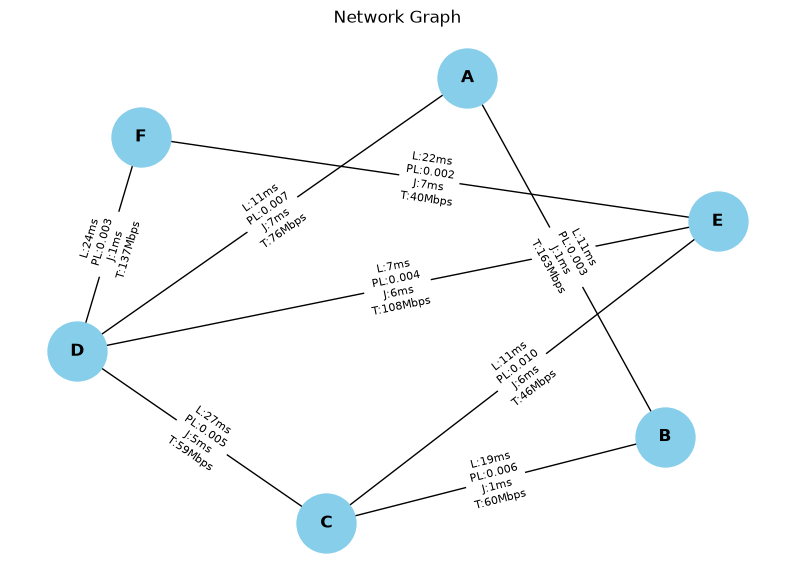

In [23]:
G = nx.Graph()
G.add_nodes_from(chr(65+i) for i in range(V))

for i in range(V - 1):
    G.add_edge(chr(65+i), chr(65+i + 1))    # create a path from node 0 to node 5

for i in range(V):
    for j in range(i + 2, V):
        if random.random() < 0.2:
            G.add_edge(chr(65+i), chr(65+j))    # random edges

for u, v in G.edges():  # adding qos constraints to each edge
    G[u][v]["latency"] = random.randint(5, 30)          # ms
    G[u][v]["packet_loss"] = random.uniform(0.001, 0.01) # probability 0.1-1%
    G[u][v]["jitter"] = random.randint(1, 8)             # ms
    G[u][v]["throughput"] = random.randint(20, 200)      # Mbps

SOURCE = chr(65)  # 'A'
DESTINATION = chr(65 + V - 1)  

draw_network_graph(G, "Network Graph")

In [24]:
edges = list(G.edges())
vertices = list(G.nodes())

V = len(vertices)
E = len(edges)

degree = {v: 0 for v in vertices}

for u, v in edges:
    degree[u] += 1
    degree[v] += 1

degree

{'A': 2, 'B': 2, 'C': 3, 'D': 4, 'E': 3, 'F': 2}

In [25]:
vertices_without_source_destination = list(filter(lambda item: item not in [SOURCE, DESTINATION], vertices))
vertices_without_source_destination

['B', 'C', 'D', 'E']

### **<u>Define QUBO problem</u>** 

In [26]:
qp = QuadraticProgram("Shortest_Path_QUBO")

x = {} # binary variable for each edge

for i, (u, v) in enumerate(edges):
    x[(u, v)] = f"({u},{v})"
    qp.binary_var(name=x[(u, v)])

y = {} # auxiliary variables
for vertex in vertices_without_source_destination:
    y[vertex] = f"include_{vertex}"
    qp.binary_var(name=y[vertex])

In [27]:
# QoS limits (end-to-end constraints)
MAX_LATENCY = 100       # ms
MAX_PACKET_LOSS = 0.02  # 2% end-to-end probability
MAX_JITTER = 25         # ms (additive jitter approximation)
MIN_THROUGHPUT = 20     # Mbps (minimum throughput on every selected link)

# weighted, normalized multi-objective cost 
W_LATENCY, W_LOSS, W_JITTER, W_THROUGHPUT = 0.3, 0.2, 0.2, 0.43

# Convert packet loss to an additive link cost:
# P_path = 1 - product(1 - p_e), so -ln(1-P_path) = sum(-ln(1-p_e))
pkt_loss_cost = {(u, v): -math.log(1 - G[u][v]["packet_loss"]) for u, v in edges}
MAX_PKT_LOSS_COST = -math.log(1 - MAX_PACKET_LOSS)

total_edge_cost = {}
for u, v in edges:  # O(E) complexity
    total_edge_cost[x[(u, v)]] = (
        W_LATENCY * G[u][v]["latency"] / MAX_LATENCY
        + W_LOSS * pkt_loss_cost[(u, v)] / MAX_PKT_LOSS_COST
        + W_JITTER * G[u][v]["jitter"] / MAX_JITTER
        + W_THROUGHPUT * (1 - MIN_THROUGHPUT / G[u][v]["throughput"])  # inverse for throughput 
    )
    G[u][v]["weight"] = total_edge_cost[x[(u, v)]]

total_edge_cost

{'(A,B)': 0.44891578793785747,
 '(A,D)': 0.47981261388301255,
 '(B,C)': 0.4142656174495276,
 '(C,D)': 0.45290519258948037,
 '(C,E)': 0.41968847534797116,
 '(D,E)': 0.4632173638540291,
 '(D,F)': 0.48075064803097434,
 '(E,F)': 0.35804364645745623}

In [28]:
qp.minimize(linear=total_edge_cost)

# source degree = 1
qp.linear_constraint(
    linear={
        x[(u, v)]: 1
        for u, v in edges
        if u == SOURCE or v == SOURCE
    },
    sense="==",
    rhs=1,
    name="must_start_from_source"
)

# destination degree = 1
qp.linear_constraint(
    linear={
        x[(u, v)]: 1
        for u, v in edges
        if u == DESTINATION or v == DESTINATION
    },
    sense="==",
    rhs=1,
    name="must_end_at_destination"
)

# intermediate nodes must have degree 0 or 2
# degree = 0 or 2
for vertex in vertices_without_source_destination:
    degree_constraint = {
        x[(u, v)]: 1
        for u, v in edges
        if u == vertex or v == vertex
    }

    degree_constraint[y[vertex]] = -2

    qp.linear_constraint(
        linear=degree_constraint,
        sense="==",
        rhs=0,
        name=f"degree_constraint_{vertex}"
    )

print(qp.prettyprint())

Problem name: Shortest_Path_QUBO

Minimize
  0.44891578793785747*(A,B) + 0.47981261388301255*(A,D)
  + 0.4142656174495276*(B,C) + 0.45290519258948037*(C,D)
  + 0.41968847534797116*(C,E) + 0.4632173638540291*(D,E)
  + 0.48075064803097434*(D,F) + 0.35804364645745623*(E,F)

Subject to
  Linear constraints (6)
    (A,B) + (A,D) == 1  'must_start_from_source'
    (D,F) + (E,F) == 1  'must_end_at_destination'
    (A,B) + (B,C) - 2*include_B == 0  'degree_constraint_B'
    (B,C) + (C,D) + (C,E) - 2*include_C == 0  'degree_constraint_C'
    (A,D) + (C,D) + (D,E) + (D,F) - 2*include_D == 0  'degree_constraint_D'
    (C,E) + (D,E) + (E,F) - 2*include_E == 0  'degree_constraint_E'

  Binary variables (12)
    (A,B) (A,D) (B,C) (C,D) (C,E) (D,E) (D,F) (E,F) include_B include_C
    include_D include_E



In [29]:
penalty = 10000

converter = QuadraticProgramToQubo(penalty=penalty)
qubo = converter.convert(qp)
print(qubo.prettyprint())

Problem name: Shortest_Path_QUBO

Minimize
  20000*(A,B)^2 + 20000*(A,B)*(A,D) + 20000*(A,B)*(B,C) - 40000*(A,B)*include_B
  + 20000*(A,D)^2 + 20000*(A,D)*(C,D) + 20000*(A,D)*(D,E) + 20000*(A,D)*(D,F)
  - 40000*(A,D)*include_D + 20000*(B,C)^2 + 20000*(B,C)*(C,D)
  + 20000*(B,C)*(C,E) - 40000*(B,C)*include_B - 40000*(B,C)*include_C
  + 20000*(C,D)^2 + 20000*(C,D)*(C,E) + 20000*(C,D)*(D,E) + 20000*(C,D)*(D,F)
  - 40000*(C,D)*include_C - 40000*(C,D)*include_D + 20000*(C,E)^2
  + 20000*(C,E)*(D,E) + 20000*(C,E)*(E,F) - 40000*(C,E)*include_C
  - 40000*(C,E)*include_E + 20000*(D,E)^2 + 20000*(D,E)*(D,F)
  + 20000*(D,E)*(E,F) - 40000*(D,E)*include_D - 40000*(D,E)*include_E
  + 20000*(D,F)^2 + 20000*(D,F)*(E,F) - 40000*(D,F)*include_D + 20000*(E,F)^2
  - 40000*(E,F)*include_E + 40000*include_B^2 + 40000*include_C^2
  + 40000*include_D^2 + 40000*include_E^2 - 19999.551084212064*(A,B)
  - 19999.52018738612*(A,D) + 0.4142656174495276*(B,C)
  + 0.45290519258948037*(C,D) + 0.41968847534797116*(C,E)

In [30]:
n = qubo.get_num_vars()

print("QUBO variables:", n)

QUBO variables: 12


In [31]:
# extract QUBO matrix and constant from the converted QuadraticProgram
qubo_matrix = qubo.objective.quadratic.to_array()
qubo_linear = qubo.objective.linear.to_array()
qubo_constant = qubo.objective.constant

Q = qubo_matrix.copy()

for i in range(len(qubo_linear)):
    Q[i, i] += qubo_linear[i]

print("QUBO matrix:\n", Q)
print("QUBO constant:", qubo_constant)

QUBO matrix:
 [[ 4.48915788e-01  2.00000000e+04  2.00000000e+04  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  -4.00000000e+04  0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  4.79812614e-01  0.00000000e+00  2.00000000e+04
   0.00000000e+00  2.00000000e+04  2.00000000e+04  0.00000000e+00
   0.00000000e+00  0.00000000e+00 -4.00000000e+04  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  2.00004143e+04  2.00000000e+04
   2.00000000e+04  0.00000000e+00  0.00000000e+00  0.00000000e+00
  -4.00000000e+04 -4.00000000e+04  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  2.00004529e+04
   2.00000000e+04  2.00000000e+04  2.00000000e+04  0.00000000e+00
   0.00000000e+00 -4.00000000e+04 -4.00000000e+04  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   2.00004197e+04  2.00000000e+04  0.00000000e+00  2.00000000e+04
   0.00000000e+00 -4.00000000e+04  0.00000000e+00 -4.00000

In [32]:
variables = qubo.variables
variables

[<Variable: (A,B) (binary)>,
 <Variable: (A,D) (binary)>,
 <Variable: (B,C) (binary)>,
 <Variable: (C,D) (binary)>,
 <Variable: (C,E) (binary)>,
 <Variable: (D,E) (binary)>,
 <Variable: (D,F) (binary)>,
 <Variable: (E,F) (binary)>,
 <Variable: include_B (binary)>,
 <Variable: include_C (binary)>,
 <Variable: include_D (binary)>,
 <Variable: include_E (binary)>]

### **<u>Run grover adaptive search</u>** 

In [33]:
gas = GroverAdaptiveSearch(Q=Q, constant=qubo_constant)
best_solution, best_value = gas.run()

print("\n> FINAL RESULT")
for var, value in zip(variables, best_solution):
    print(f"{var} = {value}")

print("Optimal QUBO value:", best_value)

Initial solution: [0 0 0 0 1 0 0 1 1 1 0 0]
Initial cost: 100000.7777321218

> Starting Grover Adaptive Search for 12 rounds

{'Round': 1, 'Grover_iterations': 0, 'Candidate': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'Candidate_cost': 20000.0, 'Best_solution': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'Best_cost': 20000.0, 'Improved': True, 'm': 1.0}
{'Round': 2, 'Grover_iterations': 0, 'Candidate': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'Candidate_cost': 20000.0, 'Best_solution': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'Best_cost': 20000.0, 'Improved': False, 'm': 1.2}
{'Round': 3, 'Grover_iterations': 0, 'Candidate': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'Candidate_cost': 20000.0, 'Best_solution': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'Best_cost': 20000.0, 'Improved': False, 'm': 1.44}
{'Round': 4, 'Grover_iterations': 0, 'Candidate': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'Candidate_cost': 20000.0, 'Best_solution': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'Best_cost': 20000.0, 'Improved': False, 

In [34]:
selected_edges = []

print("> Selected Edges:")
for i, (u, v) in enumerate(edges):
    if best_solution[i] > 0.5:
        selected_edges.append((u, v))
print(selected_edges)

> Selected Edges:
[('A', 'D'), ('D', 'F')]


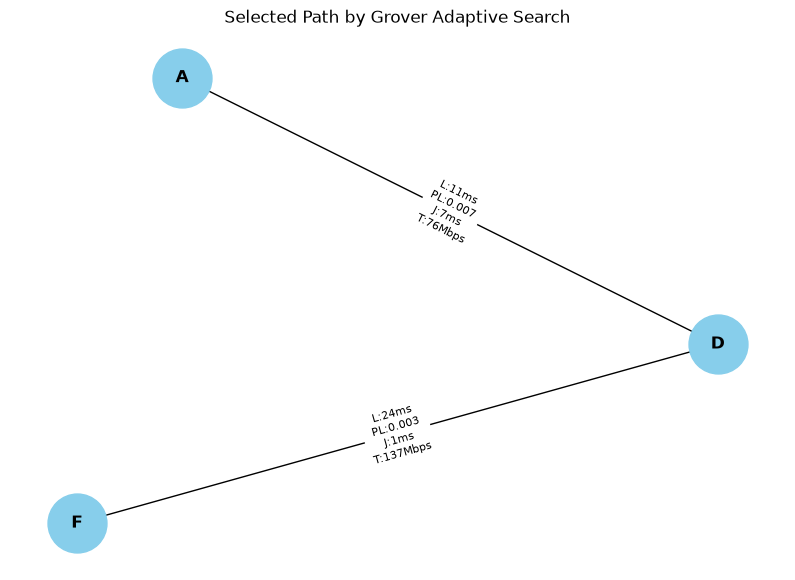

In [35]:
R = nx.Graph()
R.add_edges_from((u, v, G[u][v]) for u, v in selected_edges)
draw_network_graph(R, "Selected Path by Grover Adaptive Search")

### **<u>Shortest route classically</u>** 


> Classical Dijkstra Result
Route: ['A', 'D', 'F']
Cost: 0.9605632619139869


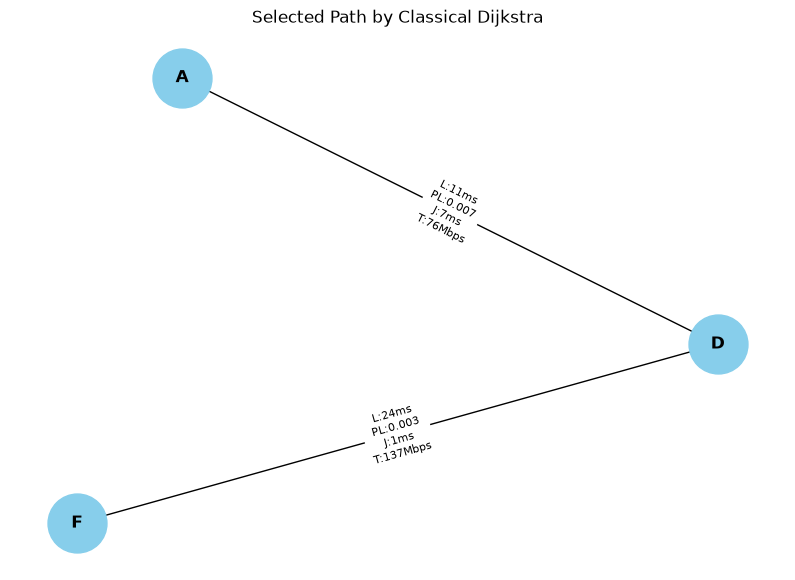

In [36]:
classical_route = nx.shortest_path(G, source=SOURCE, target=DESTINATION, weight="weight")   # default is dijkistra
classical_cost = nx.shortest_path_length(G, source=SOURCE, target=DESTINATION, weight="weight")

print("\n> Classical Dijkstra Result")
print("Route:", classical_route)
print("Cost:", classical_cost)

D = nx.Graph()
classical_edges = list(zip(classical_route[:-1], classical_route[1:]))
D.add_edges_from((u, v, G[u][v]) for u, v in classical_edges)
draw_network_graph(D, "Selected Path by Classical Dijkstra")